# D7041E Applied Artificial Intelligence Lab 1
Dominic Addo - domadd-2@student.ltu.se <br>
Abdalrahman Nasser - abdnas-2@student.ltu.se


In [1]:
import numpy as np, time
from matplotlib import pyplot as plt
from keras.datasets import mnist
from pathlib import Path
from PIL import Image
from sklearn.model_selection import KFold
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import itertools
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

## Task 1

### Task 1.1

#### Loading My Dataset and making an (n, x, y, 3) array

In [2]:
IMG_DIR = Path("C:/Users/addod/Applied AI Lab work/lab1_fundamentals_ML_NLP/Lab1_photos")  
EXTS = {".jpeg"}

try:
    # Samla bildsökvägar deterministiskt
    paths = sorted((p for p in IMG_DIR.rglob("*") if p.suffix.lower() in EXTS),
               key=lambda p: p.as_posix().lower())
except FileNotFoundError:
    print(f"Directory not found: {IMG_DIR}")
    
n = len(paths)
print(f"Found {n} images.")

# Förbered en tom array för bilderna
X = np.empty((n, 28, 28, 3), dtype=np.uint8)

for i, p in enumerate(paths):
    img = Image.open(p)
    img = img.convert("RGB")
    img = img.resize((28, 28), Image.BILINEAR) 
    X[i] = np.asarray(img, dtype=np.uint8)

print("Shape:", X.shape, "| dtype:", X.dtype) 

Found 25 images.
Shape: (25, 28, 28, 3) | dtype: uint8


#### PlotSample function

In [3]:
def PlotSample(index, X):
    """Plotta provet X[index] (form: 28x28x3)."""
    plt.figure()
    plt.imshow(X[index])
    plt.axis("off")
    plt.show()

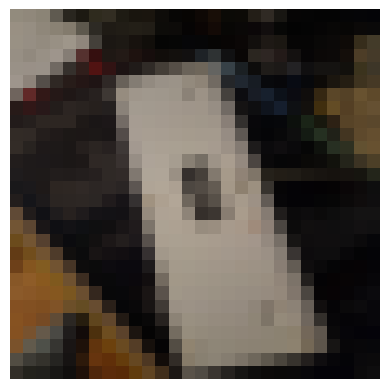

In [4]:
PlotSample(2, X)

#### Dimensionality reduction

In [5]:
n, h, w, c = X.shape          # t.ex. (n, 28, 28, 3)
X2D = X.reshape(n, h*w*c)
print(X2D.shape)

(25, 2352)


#### Rescaling by dividing to 255

In [6]:
X_norm = X2D / 255.
print ('X.min()', X_norm.min())
print ('X.max()', X_norm.max())

X.min() 0.00784313725490196
X.max() 0.9803921568627451


#### Mean subtraction

In [7]:
X_norm.mean(axis=0).shape
X_norm.mean(axis=0)
X_norm = X_norm - X_norm.mean(axis=0)
X_norm.mean(axis=0)

array([5.55111512e-17, 0.00000000e+00, 5.77315973e-17, ...,
       4.55191440e-17, 6.55031585e-17, 1.22124533e-17], shape=(2352,))

#### Calculate the Covariance Matrix

In [8]:
cov = np.cov(X_norm, rowvar=False, bias=True)
cov.shape

(2352, 2352)

#### Singular Value Decomposition (SVD)

In [9]:
U,S,V = np.linalg.svd(cov)
print('U.shape:', U.shape, 'S.shape:', S.shape, 'V.shape:', V.shape)

U.shape: (2352, 2352) S.shape: (2352,) V.shape: (2352, 2352)


#### Apply ZCA Whitening Transformation

In [10]:
epsilon = 0.1e-19
X_ZCA = U.dot(np.diag(1.0/np.sqrt(S + epsilon))).dot(U.T).dot(X_norm.T).T
print('X_ZCA.min()', X_ZCA.min())
print('X_ZCA.max()', X_ZCA.max())

X_ZCA.min() -0.5204780594795011
X_ZCA.max() 0.5330047947354615


#### Final Rescaling

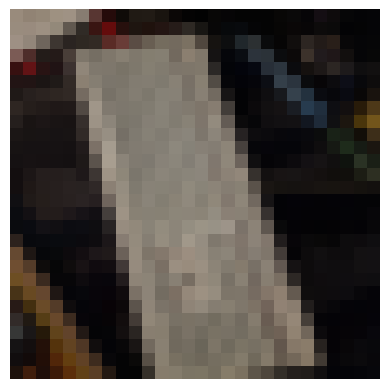

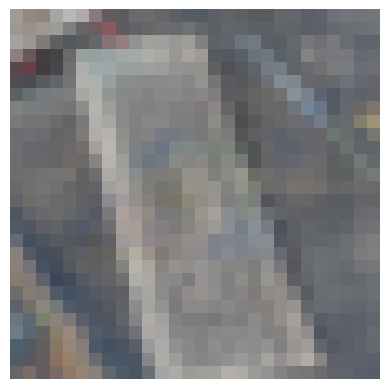

In [11]:
X_ZCA_rescaled = (X_ZCA - X_ZCA.min()) / (X_ZCA.max() - X_ZCA.min())
PlotSample(3, X)
PlotSample(3, X_ZCA_rescaled.reshape(n, h, w, c))

### Task 1.2
#### Loading the vecs.npy file

In [12]:
t0 = time.perf_counter()
try:
    data = np.load('vecs.npy', allow_pickle=True).item()
except FileNotFoundError:
    print("vecs.npy not found.")
t1 = time.perf_counter()

print(f"Loading time: {t1 - t0:.4f} seconds")

Loading time: 0.1134 seconds


#### Forming two Numpy arrays: One for the embeddings and another for the labels

In [13]:
def loadDataIntoArray(position):
    
    if position not in data:
        raise ValueError(f"Position {position} not found in the data.")
    
    embeddings = []
    labels = []
    
    digitsDic = data[position]
    for digit, embedding in digitsDic.items():
        embeddings.extend(embedding)
        labels.extend([int(digit)])

    embeddingsArray = np.array(embeddings)
    labelsArray = np.array(labels)
    
    return embeddingsArray, labelsArray

position = "3_pos" # Example position key
embeddingsArray, labelsArray = loadDataIntoArray(position)
print("Embeddings:", embeddingsArray)
print("Labels:", labelsArray)

Embeddings: [[-0.      -0.      -0.      ... -0.      -0.      -0.     ]
 [-0.      69.77938 -0.      ... -0.      -0.      -0.     ]
 [-0.      -0.      -0.      ... -0.      -0.      -0.     ]
 ...
 [-0.      -0.       0.      ... -0.      -0.      -0.     ]
 [-0.      -0.      -0.      ... -0.      -0.      -0.     ]
 [-0.      -0.      -0.      ... -0.      -0.      -0.     ]]
Labels: [0 1 2 3 4 5 6 7 8 9]


#### Shuffling the order of data and the labels

In [14]:
def shuffleData(position):
    
    embeddings, labels = loadDataIntoArray(position)

    permutation = np.random.permutation(len(labels))
    shuffledEmbeddings = embeddings[permutation]
    shuffledLabels = labels[permutation]

    return shuffledEmbeddings, shuffledLabels
shuffledEmbeddings, shuffledLabels = shuffleData(position)
print("Shuffled Embeddings:", shuffledEmbeddings)
print("Shuffled Labels:", shuffledLabels)

Shuffled Embeddings: [[-0.       -0.       -0.       ... -0.       -0.       -0.      ]
 [-0.       69.77938  -0.       ... -0.       -0.       -0.      ]
 [-0.       -0.       -0.       ... -0.       -0.       -0.      ]
 ...
 [-0.       -0.       -0.       ... -0.       -0.       -0.      ]
 [-0.       -0.       -0.       ... -0.       -0.       -0.      ]
 [-0.       63.469498 -0.       ... -0.       -0.       -0.      ]]
Shuffled Labels: [0 1 6 5 3 4 7 8 2 9]


---
### Task 2.1 Workiing with K-NN
#### Loading the MNIST dataset

In [15]:
(Xtr, Ltr), (X_test, L_test)=mnist.load_data()
print("Length of MNIST training set:", len(Xtr)+len(X_test))
print(f"Training set size: {Xtr.shape[0]}, Test set size: {X_test.shape[0]}")

Length of MNIST training set: 70000
Training set size: 60000, Test set size: 10000


#### Training set shape
Inspect Xtr.shape to confirm the number of samples and image dimensions.

In [16]:
print("Xtr.shape:", Xtr.shape)
print(f"Samples: {Xtr.shape[0]}, Height: {Xtr.shape[1]}, Width: {Xtr.shape[2]}")

Xtr.shape: (60000, 28, 28)
Samples: 60000, Height: 28, Width: 28


#### Visualizing some samples from the training dataset

Printing image number: 43817 from the MNIST dataset.


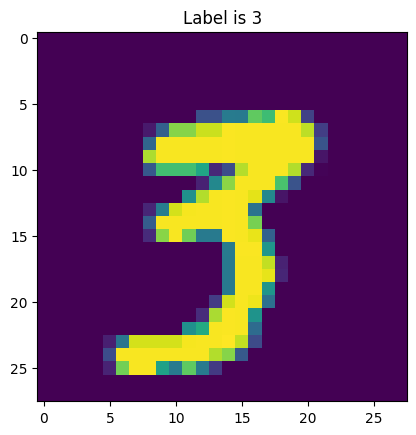

In [17]:
import random

rand = random.randint(0, Xtr.shape[0]-1)

Image=Xtr[rand,:,:]
Label=Ltr[rand]

print("Printing image number:", rand, "from the MNIST dataset.")
plt.title('Label is {Label}'.format(Label=Label))
plt.imshow(Image)

plt.show()
plt.close()


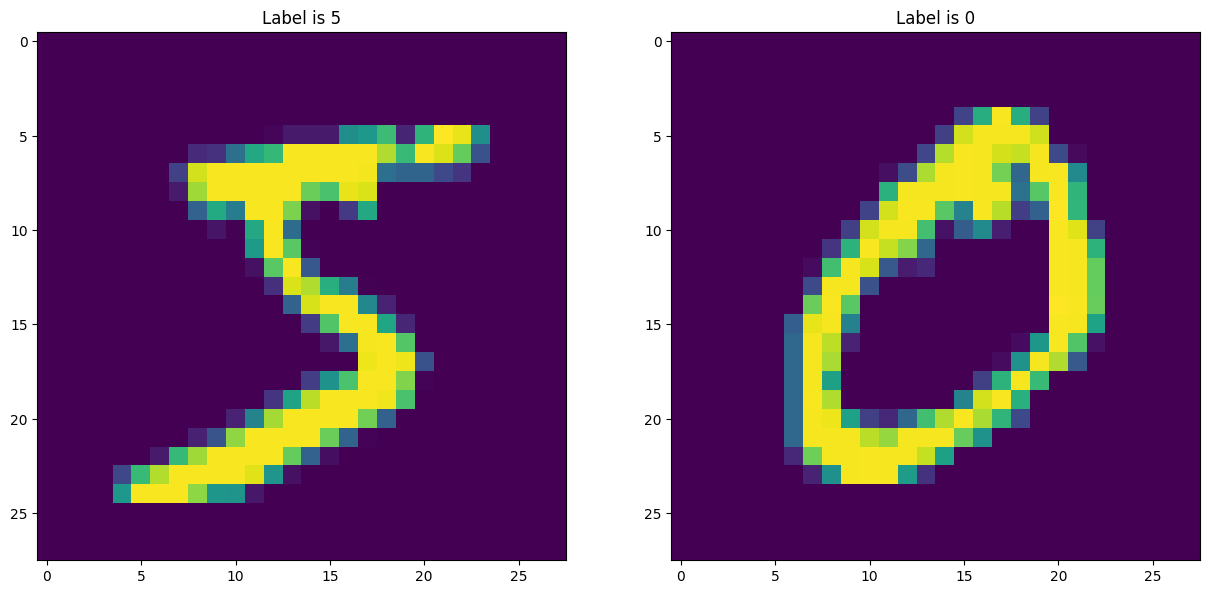

In [18]:
fig, ax=plt.subplots(nrows=1, ncols=2, figsize=(15,15))
ax0=plt.subplot(1,2,1)
ax1=plt.subplot(1,2,2)

Image=Xtr[0,:,:]
Label=Ltr[0]
Image1=Xtr[1,:,:]
Label1=Ltr[1]

ax0.set_title('Label is {Label}'.format(Label=Label))
ax0.imshow(Image)
ax1.set_title('Label is {Label}'.format(Label=Label1))
ax1.imshow(Image1)

plt.show()
plt.close()

In [19]:
28*28

784

In [20]:
#Training phase
num_sample=500
Tr_set=Xtr[:num_sample,:,:]
Ltr_set=Ltr[:num_sample]
print("Initial Training set shape:", Tr_set.shape)

Tr_set=Tr_set.reshape(num_sample,Tr_set.shape[1]*Tr_set.shape[2])
print("Training set after reshaping to 1D:", Tr_set.shape)

Initial Training set shape: (500, 28, 28)
Training set after reshaping to 1D: (500, 784)


#### Running the 1-NN classifier

In [21]:
def predict(X):
    num_test=X.shape[0]
    Lpred=np.zeros(num_test, dtype=Ltr_set.dtype)
    
    for i in range(num_test):
        distances=np.sum(np.abs(Tr_set-X[i,:]),axis=1)
        
        min_index= np.argmin(distances)
        Lpred[i]=Ltr_set[min_index]
    return Lpred

In [22]:
Test_images=X_test.reshape(X_test.shape[0],X_test.shape[1]* X_test.shape[2])
Labels_predicted=predict(Test_images)

print("Accuracy:", np.mean(Labels_predicted==L_test))

Accuracy: 0.2649


#### Modifying the code to use L2 Norm

In [23]:
def predict_l2norm(X):
    num_test=X.shape[0]
    Lpred=np.zeros(num_test, dtype=Ltr_set.dtype)
    
    for i in range(num_test):
        #distances=np.sum(np.abs(Tr_set-X[i,:]),axis=1)
        distances=np.sqrt(np.sum(np.square(np.abs(Tr_set-X[i,:])),axis=1))
        
        min_index= np.argmin(distances)
        Lpred[i]=Ltr_set[min_index]
    return Lpred

In [24]:
Test_images=X_test.reshape(X_test.shape[0],X_test.shape[1]* X_test.shape[2])
Labels_predicted_l2=predict_l2norm(Test_images)

print("Accuracy:", np.mean(Labels_predicted_l2==L_test))

Accuracy: 0.19


#### Fixing the bug

In [25]:
#Training phase
num_sample=500
Tr_set=Xtr[:num_sample,:,:]
Ltr_set=Ltr[:num_sample]

#Tr_set=Tr_set.reshape(num_sample,Tr_set.shape[1]*Tr_set.shape[2])

Tr_set=Tr_set.reshape(num_sample,Tr_set.shape[1]*Tr_set.shape[2]).astype(int)
print("Training set after reshaping to 1D:", Tr_set.shape)

Training set after reshaping to 1D: (500, 784)


In [26]:
Test_images=X_test.reshape(X_test.shape[0],X_test.shape[1]* X_test.shape[2]).astype(int)
Labels_predicted=predict(Test_images)

print("Accuracy:", np.mean(Labels_predicted==L_test))

Accuracy: 0.811


Bug is resolved due to the training set's values being set as uint8. We had an integer overflow problem, which caused the previous accuracy. Noticing from the HINT given that summing along axis 1 would not work as intended also helped.

In [27]:
Test_images=X_test.reshape(X_test.shape[0],X_test.shape[1]* X_test.shape[2]).astype(int)
Labels_predicted_l2=predict_l2norm(Test_images)

print("Accuracy:", np.mean(Labels_predicted_l2==L_test))

Accuracy: 0.8294


#### Extending the NN classifier into a k-NN

In [28]:
def kNN_predict(testSet, trainingSet, trainingLabel, k_nearest):
    numerable = testSet.shape[0]
    Lpred = np.zeros(numerable, dtype=trainingLabel.dtype)
    
    # cast as int to not get bugs like before
    testSet = testSet.astype(int)
    trainingSet = trainingSet.astype(int)
    for i in range(numerable):
        distances = np.sqrt(np.sum((trainingSet - testSet[i, :]) ** 2, axis=1)) # L2
        nearest_indices = np.argsort(distances)[:k_nearest]
        nearest_labels = trainingLabel[nearest_indices]
        label_counts = np.bincount(nearest_labels, minlength=10)
        
        # break ties if needed.
        if np.count_nonzero(label_counts == label_counts.max()) > 1:
            # nearest neighbor wins in case of a tie
            winner = trainingLabel[nearest_indices[0]]
        else:
            winner = np.argmax(label_counts)
        Lpred[i] = winner
    
    return Lpred

In [29]:
k = 4
Labels_predicted_k=kNN_predict(Test_images, Tr_set, Ltr_set, k)
print("Accuracy:", np.mean(Labels_predicted_k==L_test), "for k =", k)

Accuracy: 0.8196 for k = 4


### Task 2.2

#### Extending the code with necessary methods to find the best value of k using 3-fold cross-validation method

In [30]:
def kNN_predict(testSet, trainingSet, trainingLabel, k_nearest):
    numerable = testSet.shape[0]
    Lpred = np.zeros(numerable, dtype=trainingLabel.dtype)

    for i in range(numerable):
        distances = np.sqrt(np.sum((trainingSet - testSet[i, :]) ** 2, axis=1)) # L2
        nearest_indices = np.argsort(distances)[:k_nearest]
        nearest_labels = trainingLabel[nearest_indices]
        label_counts = np.bincount(nearest_labels, minlength=10)
        
        # break ties if needed.
        if np.count_nonzero(label_counts == label_counts.max()) > 1:
            winner = trainingLabel[nearest_indices[0]]
        else:
            winner = np.argmax(label_counts)
        Lpred[i] = winner
    
    return Lpred

In [31]:
def find_optimal_k(training_set, training_labels, k_values, num_folds=3):
    best_k = None
    best_accuracy = 0
    accuracies_for_k = {k: [] for k in k_values}    

    kf = KFold(n_splits=num_folds, shuffle=True, random_state=1)
    
    for k in k_values:
        fold_accuracies = []
        
        for train_index, val_index in kf.split(training_set):
            X_train_fold, X_val_fold = training_set[train_index], training_set[val_index]
            y_train_fold, y_val_fold = training_labels[train_index], training_labels[val_index]
            
            predictions = kNN_predict(X_val_fold, X_train_fold, y_train_fold, k)
            
            accuracy = np.mean(predictions == y_val_fold)
            fold_accuracies.append(accuracy) 
        
        avg_accuracy = np.mean(fold_accuracies)
        accuracies_for_k[k].append(avg_accuracy)
        
        if avg_accuracy > best_accuracy:
            best_accuracy = avg_accuracy
            best_k = k
    
    return best_k, best_accuracy, accuracies_for_k

In [32]:
k_values = list(range(1, 11)) # adjust k in the range 1 to 11 (more than enough for these tests)

# find the optimal k
best_k, best_accuracy, accuracies_for_k = find_optimal_k(Tr_set, Ltr_set, k_values)

print(f"Optimal k: {best_k} with cross-validated accuracy: {best_accuracy} is the best\n")

accuracies_for_k_cleaned = {k: [float(acc) for acc in accuracies] for k, accuracies in accuracies_for_k.items()}
print("Accuracies for each tested k:")
for i in accuracies_for_k_cleaned:
    print(f"k=",i,": ", accuracies_for_k_cleaned[i])

Optimal k: 4 with cross-validated accuracy: 0.8680229901642499 is the best

Accuracies for each tested k:
k= 1 :  [0.8560589664045403]
k= 2 :  [0.8560589664045403]
k= 3 :  [0.8620229420676718]
k= 4 :  [0.8680229901642499]
k= 5 :  [0.8280427097612004]
k= 6 :  [0.8379987013923959]
k= 7 :  [0.8220306375201405]
k= 8 :  [0.8199985571026621]
k= 9 :  [0.8040064449414425]
k= 10 :  [0.8059904287809921]


---
### Task 3
#### Task 3.1

In [33]:
iris_data=load_iris()

print(f"Total number of data points: {len(iris_data.data)}\nShape of data: {iris_data.data.shape}")
X, y = iris_data.data, iris_data.target
feature_names, classes = iris_data.feature_names, iris_data.target_names
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training and test set shape: {X_train.shape}, {y_train.shape}, {X_test.shape}, {y_test.shape}")

print(f"Feature names: {feature_names}")
print(f"Classes: {classes}")

Total number of data points: 150
Shape of data: (150, 4)
Training and test set shape: (120, 4), (120,), (30, 4), (30,)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']


#### Confusion matrix function to plot confusion matrix

In [34]:
def plot_confusion_matrix(cm, title, ax):
    ax.imshow(cm, cmap='Blues', interpolation='nearest')
    ax.set_title(title)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    ax.set_xticks(np.arange(len(classes)))
    ax.set_yticks(np.arange(len(classes)))
    ax.set_xticklabels(classes, rotation=45)
    ax.set_yticklabels(classes)
    
    thresh = cm.max() / 2
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        ax.text(j, i, f'{cm[i, j]}', 
                horizontalalignment='center', 
                color='white' if cm[i, j] > thresh else 'black')

#### SVM classifiers with different kernels and approaches for multi-class classification

In [35]:
def svm_train(X_train, y_train, X_test, y_test, kernel_type, approach_type):
    svm_classifier = SVC(kernel=kernel_type, decision_function_shape=approach_type)
    svm_classifier.fit(X_train, y_train)
    predictions = svm_classifier.predict(X_test)
    
    # support_vectors = svm_classifier.support_vectors_
    
    accuracy = float(accuracy_score(y_test, predictions)) 
    cm = confusion_matrix(y_test, predictions)
    f1 = f1_score(y_test, predictions, average='weighted')
    
    return accuracy, cm, f1, svm_classifier
# support_vectors

#### Function for visualizing the decision boundaries for different features

In [36]:
def visualize_decision_boundaries(X_test, y_test, classifier, feature_names, kernel_type, ax):
    x_min, x_max = X_test[:,0].min() - 1, X_test[:, 0].max() + 1
    y_min, y_max = X_test[:, 1].min() - 1, X_test[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                         np.arange(y_min, y_max, 0.01))

    Z = classifier.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.8)
    ax.scatter(X_test[:,0], X_test[:, 1], c=y_test, edgecolors='k', s=20, marker='o')
    ax.set_xlabel(f'Feature {feature_names[0]}')
    ax.set_ylabel(f'Feature {feature_names[1]}')
    ax.set_title(f"SVM with approach ovo and kernel: {kernel_type} for features {feature_names[0]} vs. {feature_names[1]}")

#### Find the best kernel and its metrics

In [ ]:
def find_best_kernel(X_train, y_train, X_test, y_test, kernels, approaches):
    results = {}
    best_kernel = None
    best_accuracy = 0
    best_f1 = 0
    
    for kernel in kernels:
        for approach in approaches:
            accuracy, cm, f1, classifier = svm_train(X_train, y_train, X_test, y_test, kernel, approach)
            results[(kernel, approach)] = (accuracy, cm, f1, classifier)
            
            if accuracy > best_accuracy:
                best_accuracy = accuracy
                best_f1 = f1
                best_kernel = (kernel, approach)
                
    return best_kernel, best_accuracy, best_f1, results

In [38]:
kernels = ['linear', 'poly', 'rbf']
approaches = ['ovo', 'ovr']

best_kernel, best_accuracy, best_f1, results = find_best_kernel(X_train, y_train, X_test, y_test, 
                                                     kernels=kernels, 
                                                     approaches=approaches)
print(f"Best kernel: {best_kernel}")
print(f"Best accuracy: {best_accuracy}")
print(f"Best f1: {best_f1}")

Best kernel: ('linear', 'ovo')
Best accuracy: 1.0
Best f1: 1.0


### Function to extract the support vectors for each class in ovr approach

In [39]:
def extract_support_vectors(classifier, approach_type):
    if approach_type == 'ovr':
        support_vectors = {}
        
        start_idx = 0
        for i, class_label in enumerate(classifier.classes_):
            end_idx = start_idx + classifier.n_support_[i]
            support_vectors[class_label] = classifier.support_vectors_[start_idx:end_idx]
            start_idx = end_idx
        return support_vectors
    else:
        return classifier.support_vectors_

In [43]:
accuracy, cm, f1, classifier = svm_train(X_train, y_train, X_test, y_test, kernel_type='linear', approach_type='ovr')
support_vectors = extract_support_vectors(classifier, approach_type='ovr')
for class_label, sv in support_vectors.items():
    print(f"Class {class_label}'s {len(sv)} support vectors: \n{sv}\n")

Class 0's 3 support vectors: 
[[4.8 3.4 1.9 0.2]
 [5.1 3.3 1.7 0.5]
 [4.5 2.3 1.3 0.3]]

Class 1's 11 support vectors: 
[[5.6 3.  4.5 1.5]
 [5.4 3.  4.5 1.5]
 [6.7 3.  5.  1.7]
 [5.9 3.2 4.8 1.8]
 [5.1 2.5 3.  1.1]
 [6.  2.7 5.1 1.6]
 [6.3 2.5 4.9 1.5]
 [6.1 2.9 4.7 1.4]
 [6.5 2.8 4.6 1.5]
 [6.9 3.1 4.9 1.5]
 [6.3 2.3 4.4 1.3]]

Class 2's 11 support vectors: 
[[6.3 2.5 5.  1.9]
 [6.3 2.8 5.1 1.5]
 [6.3 2.7 4.9 1.8]
 [6.  3.  4.8 1.8]
 [6.  2.2 5.  1.5]
 [6.2 2.8 4.8 1.8]
 [6.5 3.  5.2 2. ]
 [7.2 3.  5.8 1.6]
 [5.6 2.8 4.9 2. ]
 [5.9 3.  5.1 1.8]
 [4.9 2.5 4.5 1.7]]



#### Plotting the decision boundaries for different features

SVM with approach ovo and kernel: linear for features sepal width (cm) vs. petal length (cm)
Accuracy: 1.0000 
F1 Score: 1.0 



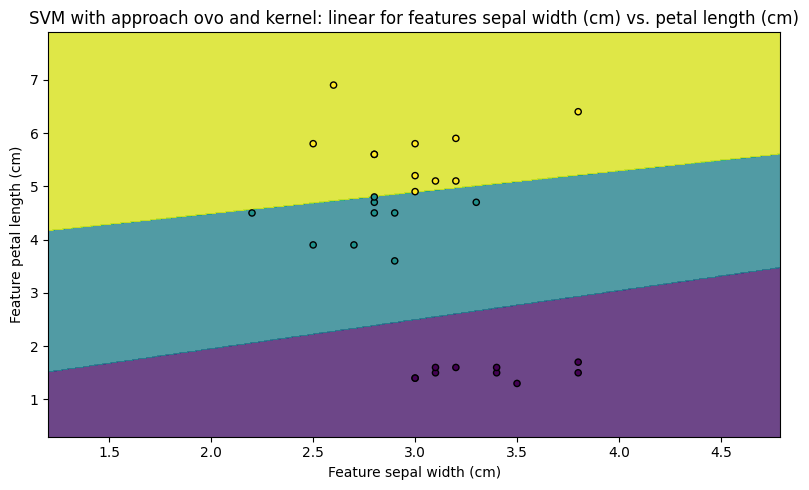

SVM with approach ovo and kernel: linear for features petal length (cm) vs. petal width (cm)
Accuracy: 1.0000 
F1 Score: 1.0 



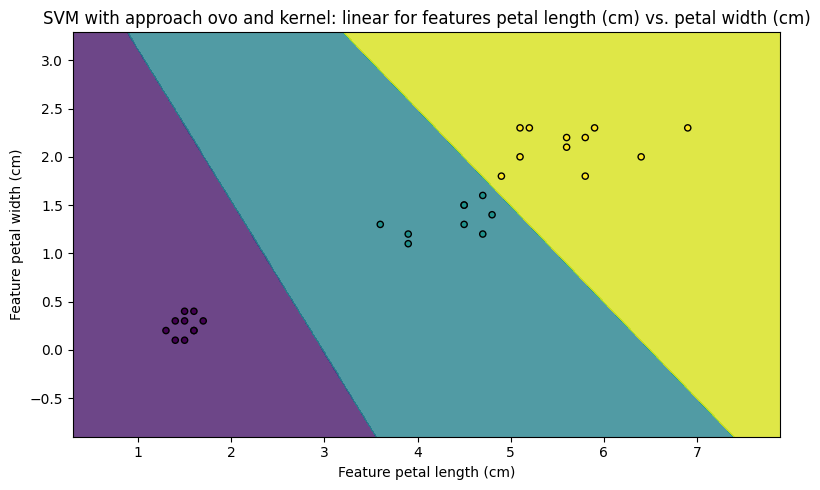

SVM with approach ovo and kernel: poly for features sepal width (cm) vs. petal length (cm)
Accuracy: 0.9667 
F1 Score: 0.966750208855472 



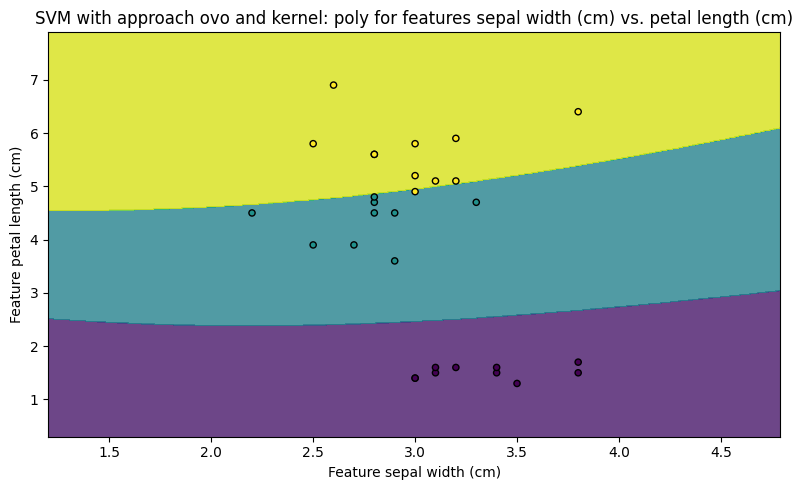

SVM with approach ovo and kernel: poly for features petal length (cm) vs. petal width (cm)
Accuracy: 1.0000 
F1 Score: 1.0 



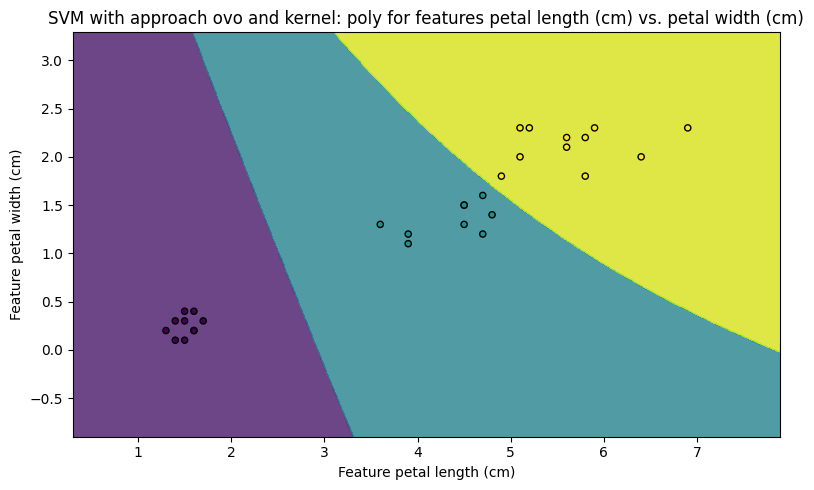

SVM with approach ovo and kernel: rbf for features sepal width (cm) vs. petal length (cm)
Accuracy: 0.9667 
F1 Score: 0.9664109121909632 



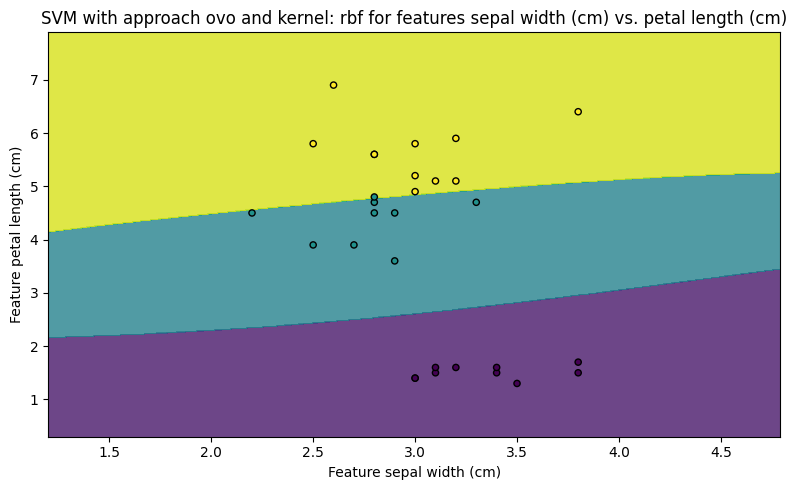

SVM with approach ovo and kernel: rbf for features petal length (cm) vs. petal width (cm)
Accuracy: 1.0000 
F1 Score: 1.0 



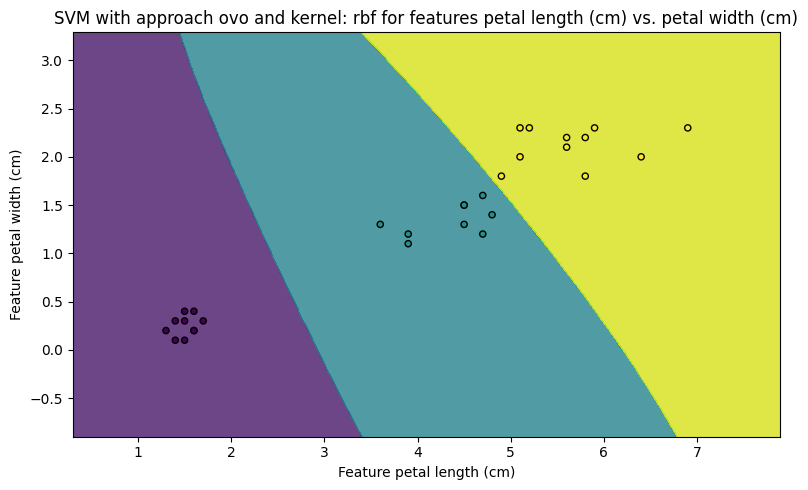

In [ ]:
kernels = ['linear', 'poly', 'rbf']
featureDimension = [(2,3), (3,4)]

for kernel in kernels:

    for i, j in featureDimension:
        
        X_train_2d = X_train[:, [i-1, j-1]]
        X_test_2d = X_test[:, [i-1, j-1]]

        accuracy, cm, f1, classifier = svm_train(X_train_2d, y_train, X_test_2d, y_test, kernel_type=kernel, approach_type='ovo')
        
        print(f"SVM with approach ovo and kernel: {kernel} for features {feature_names[i-1]} vs. {feature_names[j-1]}")
        print("Accuracy:", f"{accuracy:.4f}", "\nF1 Score:", f1, "\n")
        
        fig, ax=plt.subplots(nrows=1, ncols=1, figsize=(8,5))
        
        visualize_decision_boundaries(X_test_2d, y_test, classifier, 
                                    feature_names=[feature_names[i-1], feature_names[j-1]], kernel_type=kernel, ax=ax)
        
        plt.tight_layout()
        plt.show()

---
### Task 4

#### Task 4.1
####  Evaluating the Word2Vec results on the TOEFL Synonym task   

In [ ]:
with open("results_gensim_word2vec.txt", "r") as f:
    content = f.read()
    print(content)

Final results:

Dimension: 10
  All runs: ['43.75%', '45.00%', '47.50%', '45.00%', '48.75%', '48.75%', '46.25%', '51.25%', '50.00%', '50.00%']
  Average:  47.62%
  Std Dev:  2.40%
  Min:      43.75%
  Max:      51.25%
Dimension: 100
  All runs: ['70.00%', '65.00%', '66.25%', '66.25%', '67.50%', '68.75%', '70.00%', '67.50%', '66.25%', '66.25%']
  Average:  67.38%
  Std Dev:  1.62%
  Min:      65.00%
  Max:      70.00%
Dimension: 1000
  All runs: ['67.50%', '66.25%', '65.00%', '68.75%', '67.50%', '67.50%', '65.00%', '66.25%', '65.00%', '67.50%']
  Average:  66.62%
  Std Dev:  1.26%
  Min:      65.00%
  Max:      68.75%
Dimension: 2000
  All runs: ['63.75%', '65.00%', '66.25%', '63.75%', '66.25%', '66.25%', '66.25%', '62.50%', '67.50%', '66.25%']
  Average:  65.38%
  Std Dev:  1.48%
  Min:      62.50%
  Max:      67.50%
Dimension: 4000
  All runs: ['66.25%', '66.25%', '65.00%', '65.00%', '65.00%', '63.75%', '68.75%', '65.00%', '65.00%', '65.00%']
  Average:  65.50%
  Std Dev:  1.27%
  Min

From observing the results, we can observe that the accuracy changes with the dimensionality; especially when it is on the lower side. This is due to vector space of lower dimensionality not being large enough to capture the complex replationships between words in the data. When the dimensionality increased from 10 to 100, we got the highest accuracy for the tests performed, which also suggests that 100 dimensions provide adequate expressiveness to encode meaningful word similarities. Increasing it further didn't dramatically improve the results.

#### Task 4.2

####  Evaluating the results of training word embeddings using Random Indexing on the TOEFL Synonym task

In [ ]:
with open("results_gensim_random_indexing.txt", "r") as f:
    content = f.read()
    print(content)

Final results:

Experiment start time: 2025-11-23 21:24:15
Dimension: 1000
  All runs: ['66.25%', '66.25%', '66.25%', '66.25%', '66.25%', '66.25%', '66.25%', '66.25%']
  Average:  66.25%
  Std Dev:  0.00%
  Min:      66.25%
  Max:      66.25%
Dimension: 4000
  All runs: ['71.25%', '70.00%', '70.00%', '70.00%', '70.00%', '70.00%', '70.00%', '71.25%']
  Average:  70.31%
  Std Dev:  0.54%
  Min:      70.00%
  Max:      71.25%
Dimension: 6000
  All runs: ['68.75%', '67.50%', '68.75%', '68.75%', '67.50%', '67.50%', '67.50%', '68.75%']
  Average:  68.12%
  Std Dev:  0.62%
  Min:      67.50%
  Max:      68.75%
Dimension: 8000
  All runs: ['75.00%', '76.25%', '75.00%', '75.00%', '75.00%', '75.00%', '75.00%', '75.00%']
  Average:  75.16%
  Std Dev:  0.41%
  Min:      75.00%
  Max:      76.25%
Results analysis:
Best performing dimension: 8000 with average accuracy of 75.16%



The current code works adequately only when size of window is 2. What needs to be changed in the code to overcome this issue is altering the hardcoded window size present on the first line of this code present in the main.py file:

```python
if len(lines[1]) < 2:
    if k != 1: #if one word on the left was already added
        word_space[words[i]] = np.add(word_space[words[i]], np.roll(dictionary[lines[1][0]], -1)) #update word embedding
    else:
        word_space[words[i]] = np.add(word_space[words[i]], np.roll(dictionary[lines[1][0]], -1)) #update word embedding
        word_space[words[i]] = np.add(word_space[words[i]], np.roll(dictionary[lines[0][len(lines[0]) - 1]], -1)) #update word embedding
```
This line hardcodes the window size to exactly 2 left neighbors, which causes a break in the code logic when the window size is set to eg. 3 or 5. A similarly hardcoded right neighboring window was found several lines later here: 
```python
if len(lines[3]) < 2:
    if k != 1:
        word_space[words[i]] = np.add(word_space[words[i]], np.roll(dictionary[lines[3][0]], 1)) #update word embedding
    else:
        word_space[words[i]] = np.add(word_space[words[i]], np.roll(dictionary[lines[3][0]], 1)) #update word embedding
        word_space[words[i]] = np.add(word_space[words[i]], np.roll(dictionary[lines[4][0]], 1)) #update word embedding